# Stage 7 + 8: Diffusion (Text -> Image) + Poster Assembly
## Advertisement Generation Project — Text-to-Poster Pipeline

This notebook is the final assembly stage: given only **text** (a product
title + category + description), it produces a **finished advertisement
poster** — no manual image editing involved.

**Pipeline:**
```
Product text  --[pretrained Diffusion]-->  Ad image
Product text  --[your fine-tuned Transformer]-->  Ad copy (Description/Caption/Tagline)
Ad image + Ad copy  --[Pillow compositing]-->  Finished poster
```

Diffusion here is **pretrained**, not trained on your own dataset — as
covered earlier, this is intentional: a pretrained model already knows
countless real-world backgrounds/materials/lighting setups, so it isn't
limited to whatever's in your ~7.7k product images (which, as you found,
are mostly plain backgrounds).

A bonus optional section at the end covers **inpainting** (keeping a real
uploaded product photo and generating only a new background around it),
for teams that want to go beyond pure text-to-image.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_DATA_DIR = '/content/drive/MyDrive/Adgen_dataset/ad_dataset_clean'
DRIVE_TRANSFORMER_DIR = '/content/drive/MyDrive/Adgen_dataset/transformer_results/transformer_best'
DRIVE_RESULTS_DIR = '/content/drive/MyDrive/Adgen_dataset/diffusion_poster_results'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q diffusers transformers accelerate safetensors pillow ipywidgets rembg onnxruntime

In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    print("WARNING: no GPU detected. Diffusion is very slow on CPU — go to "
          "Runtime > Change runtime type > T4 GPU before continuing.")

CUDA available: True


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


## 1. Load the pretrained Diffusion model

Using **SD-Turbo** — a fast, distilled Stable Diffusion variant that
generates a good image in a single inference step (seconds, not minutes),
which matters a lot on a free Colab GPU. If you have more GPU time and
want higher quality, swap `MODEL_ID` for `"runwayml/stable-diffusion-v1-5"`
and increase `NUM_INFERENCE_STEPS` in Section 3 to ~25–30.

In [ ]:
!pip install -q --upgrade diffusers transformers accelerate safetensors pillow ipywidgets rembg onnxruntime numpy

In [ ]:
!pip install --upgrade "diffusers[torch]" transformers accelerate peft numba scikit-image

In [ ]:
print('Uninstalling potentially conflicting packages...')
!pip uninstall -y diffusers transformers accelerate peft numba scikit-image

print('Installing known compatible versions...')
!pip install diffusers==0.27.1 transformers==4.38.2 accelerate==0.27.2 peft==0.9.0 numba==0.61.0 scikit-image==0.25.0

print('Packages reinstalled. Please restart the runtime (Runtime > Restart runtime) and then re-run all cells.')

In [ ]:
print('Uninstalling incompatible numpy version and installing a compatible one...')
!pip uninstall -y numpy
!pip install numpy==1.23.5
print('numpy version updated. Please re-run the cell where the error occurred.')

Uninstalling incompatible numpy version and installing a compatible one...
  Using cached numpy-1.23.5.tar.gz (10.7 MB)
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.
numpy version updated. Please re-run the cell where the error occurred.


In [ ]:
from diffusers import AutoPipelineForText2Image

MODEL_ID = "stabilityai/sd-turbo"

pipe = AutoPipelineForText2Image.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
)
pipe = pipe.to(device)
print(f"Loaded {MODEL_ID} on {device}")

[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Loaded stabilityai/sd-turbo on cuda


In [ ]:
from google.colab import output
output.enable_custom_widget_manager()

Support for third party widgets will remain active for the duration of the session. To disable support:

In [ ]:
from google.colab import output
output.disable_custom_widget_manager()

Add `%load_ext cudf.pandas` before importing pandas to speed up operations using GPU

In [ ]:
from google.colab import output
output.enable_custom_widget_manager()

Support for third party widgets will remain active for the duration of the session. To disable support:

In [ ]:
from google.colab import output
output.disable_custom_widget_manager()

Support for third party widgets will remain active for the duration of the session. To disable support:

In [ ]:
from google.colab import output
output.disable_custom_widget_manager()

## 2. Load your fine-tuned Transformer (for the ad copy)

Reuses the model saved to Drive at the end of the Transformer stage.

In [ ]:
import os

if os.path.exists(DRIVE_TRANSFORMER_DIR):
    from transformers import AutoTokenizer, AutoModelForCausalLM
    text_tokenizer = AutoTokenizer.from_pretrained(DRIVE_TRANSFORMER_DIR)
    text_model = AutoModelForCausalLM.from_pretrained(DRIVE_TRANSFORMER_DIR).to(device)
    text_model.eval()
    TRANSFORMER_AVAILABLE = True
    print("Loaded fine-tuned Transformer from Drive.")
else:
    TRANSFORMER_AVAILABLE = False
    print("Transformer checkpoint not found at:", DRIVE_TRANSFORMER_DIR)
    print("Run the Transformer notebook first, or captions below will use a simple fallback.")

Loading weights:   0%|          | 0/76 [00:01<?, ?it/s]

Loaded fine-tuned Transformer from Drive.


## 3. Prompt builder + image generation function

Turns raw product text into an ad-photography-style prompt. A negative
prompt steers the model away from common failure modes (blurry, watermark
text, extra limbs on any people in frame, etc.).

In [ ]:
AD_STYLE_SUFFIX = ", professional product photography, studio lighting, advertisement, high quality, sharp focus, commercial photo"
NEGATIVE_PROMPT = "blurry, low quality, watermark, text, logo, deformed, extra limbs, cropped, out of frame"

def build_image_prompt(title, category, description=""):
    base = f"{title}, {category.lower()}"
    if description:
        base += f", {description[:120]}"
    return base + AD_STYLE_SUFFIX

def generate_ad_image(title, category, description="", seed=None, num_inference_steps=1, guidance_scale=0.0):
    prompt = build_image_prompt(title, category, description)
    generator = torch.Generator(device=device).manual_seed(seed) if seed is not None else None

    image = pipe(
        prompt=prompt,
        negative_prompt=NEGATIVE_PROMPT,
        num_inference_steps=num_inference_steps,   # SD-Turbo: 1-4 steps is enough
        guidance_scale=guidance_scale,               # SD-Turbo works best with guidance_scale=0.0
        generator=generator,
    ).images[0]
    return image, prompt

## 4. Try it — one generated image per category

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['photo']


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

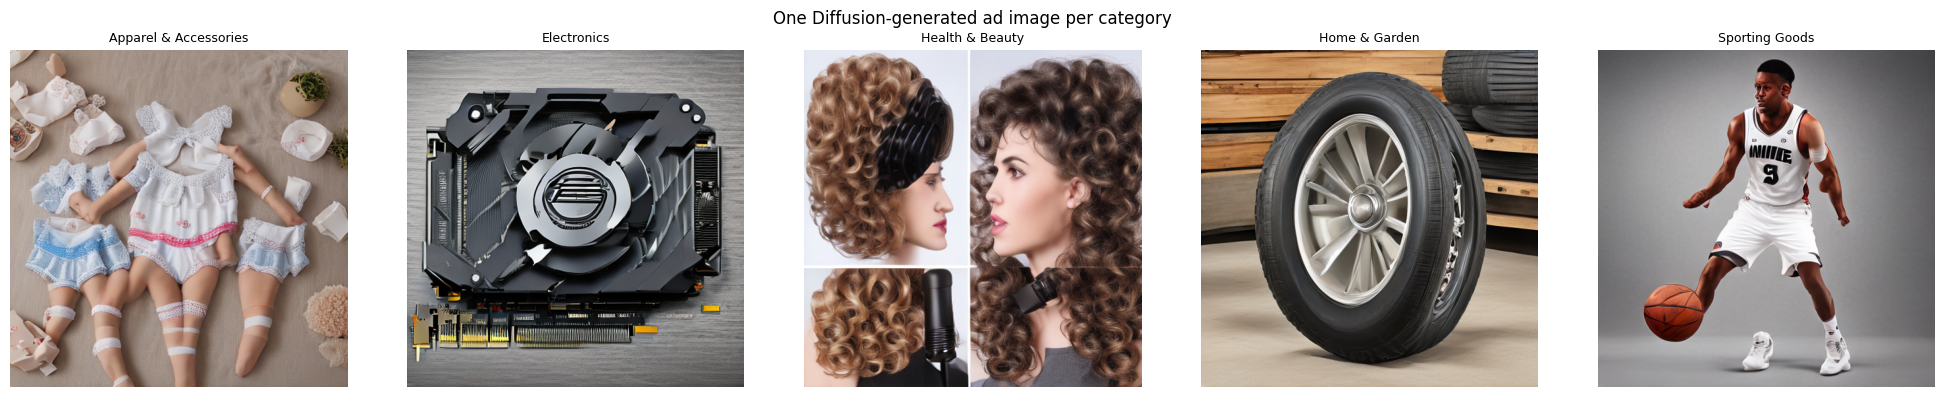

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(f"{DRIVE_DATA_DIR}/metadata_clean.csv")
sample_per_category = df.groupby("category").first().reset_index()

fig, axes = plt.subplots(1, len(sample_per_category), figsize=(4 * len(sample_per_category), 4))
for ax, (_, row) in zip(axes, sample_per_category.iterrows()):
    img, prompt = generate_ad_image(row["product_title"], row["category"], row["product_description"], seed=42)
    ax.imshow(img); ax.axis("off"); ax.set_title(row["category"], fontsize=9)
plt.suptitle("One Diffusion-generated ad image per category")
plt.tight_layout()
plt.savefig("diffusion_category_samples.png", dpi=120)
plt.show()

## 5. Ad copy generation (Transformer)

Reuses the same cleaning helpers from the Transformer notebook so output
stays in the required 3-line format. If no checkpoint was found in
Section 2, a simple deterministic fallback is used instead so the
pipeline still runs end to end.

In [ ]:
import re

def ensure_punct(s):
    s = s.strip()
    if s and s[-1] not in ".!?":
        s += "."
    return s

def generate_ad_copy(title, category, description=""):
    if not TRANSFORMER_AVAILABLE:
        return {
            "description": ensure_punct(f"The {title} is a {category.lower()} product."),
            "caption": ensure_punct(f"Discover the {title.lower()}."),
            "tagline": "Quality you can trust.",
        }

    prompt = f"Title: {title}\nCategory: {category}\nDescription: {description[:350]}\nGenerate:"
    inputs = text_tokenizer(prompt, return_tensors="pt", truncation=True, max_length=180).to(device)
    with torch.no_grad():
        out = text_model.generate(
            **inputs, max_new_tokens=90, num_beams=4,
            repetition_penalty=1.3, no_repeat_ngram_size=3,
            early_stopping=True, pad_token_id=text_tokenizer.pad_token_id,
        )
    raw = text_tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)

    def field(name, text):
        m = re.search(rf'{name}:\s*(.*)', text)
        return ensure_punct(m.group(1).strip()) if m else ""

    desc = field("Product Description", raw) or ensure_punct(f"The {title} is a {category.lower()} product.")
    cap = field("Caption", raw) or ensure_punct(f"Discover the {title.lower()}.")
    tag = field("Tagline", raw) or "Quality you can trust."
    return {"description": desc, "caption": cap, "tagline": tag}

## 6. Poster assembly (Pillow) — embedded poster-style typography

The tagline is drawn as a large, bold, outlined headline directly over the top of the generated image — like a movie-poster title — fading into the scene through a soft gradient instead of sitting on a solid banner block, so the text reads as part of the image rather than a caption pasted on top of it. The caption sits underneath as a smaller subtitle.

In [ ]:
import os, urllib.request, urllib.parse
import numpy as np
from PIL import ImageFont

FONT_DIR = "/content/fonts"
os.makedirs(FONT_DIR, exist_ok=True)

# Each entry: (path inside the google/fonts repo, local filename,
# variable-font instance to select if it's a variable font, short description)
FONT_LIBRARY = {
    "handwritten_playful": (
        "apache/permanentmarker/PermanentMarker-Regular.ttf",
        "PermanentMarker-Regular.ttf", None,
        "energetic marker scrawl -- general-purpose, DIY/casual feel"),
    "bold_impact": (
        "ofl/anton/Anton-Regular.ttf",
        "Anton-Regular.ttf", None,
        "huge condensed bold sans -- punchy tech/sale/sports headlines"),
    "clean_modern": (
        "ofl/montserrat/Montserrat[wght].ttf",
        "Montserrat.ttf", "Bold",
        "minimal geometric sans -- premium/tech/professional"),
    "elegant_luxury": (
        "ofl/playfairdisplay/PlayfairDisplay[wght].ttf",
        "PlayfairDisplay.ttf", "Bold",
        "high-contrast serif -- jewelry/watches/premium/luxury"),
    "script_romantic": (
        "ofl/dancingscript/DancingScript[wght].ttf",
        "DancingScript.ttf", "Bold",
        "flowing script -- beauty/fashion/romantic"),
    "friendly_rounded": (
        "ofl/fredoka/Fredoka[wdth,wght].ttf",
        "Fredoka.ttf", "SemiBold",
        "soft rounded sans -- kids/home/food/friendly brands"),
    "retro_fun": (
        "ofl/bangers/Bangers-Regular.ttf",
        "Bangers-Regular.ttf", None,
        "comic-bold shout -- toys/fun food/promos"),
    "industrial_bold": (
        "ofl/oswald/Oswald[wght].ttf",
        "Oswald.ttf", "Bold",
        "narrow bold sans -- sports/fitness/outdoor/industrial"),
    "casual_handwritten2": (
        "ofl/caveat/Caveat[wght].ttf",
        "Caveat.ttf", "Bold",
        "soft handwriting -- organic/handmade/warm lifestyle"),
}

# category/keyword -> ranked candidate styles (checked in this order, first match wins)
KEYWORD_RULES = [
    (["jewelry", "watch", "perfume", "luxury", "premium", "gold", "diamond"], ["elegant_luxury"]),
    (["beauty", "cosmetic", "skincare", "makeup", "fashion", "dress", "apparel", "jewel"], ["script_romantic", "elegant_luxury"]),
    (["electronics", "tech", "gadget", "smart", "digital", "camera", "laptop", "phone", "headphone", "speaker"], ["bold_impact", "clean_modern"]),
    (["sport", "fitness", "shoe", "running", "gym", "outdoor", "athletic"], ["industrial_bold", "bold_impact"]),
    (["food", "snack", "coffee", "cafe", "restaurant", "kitchen", "drink", "bakery"], ["friendly_rounded", "casual_handwritten2"]),
    (["kid", "toy", "baby", "game", "fun", "candy"], ["retro_fun", "friendly_rounded"]),
    (["home", "furniture", "decor", "handmade", "organic", "craft", "garden"], ["casual_handwritten2", "friendly_rounded"]),
]

# Which style each visual mood nudges toward -- only used as a tie-breaker
# among styles that already matched the product's category/keywords.
MOOD_PREFERENCE = {
    "dark_dramatic": ["bold_impact", "industrial_bold", "handwritten_playful"],
    "bright_minimal": ["clean_modern", "elegant_luxury"],
    "warm_vibrant": ["friendly_rounded", "casual_handwritten2", "retro_fun", "script_romantic"],
    "cool_techy": ["clean_modern", "bold_impact", "industrial_bold"],
    "soft_neutral": ["handwritten_playful", "script_romantic"],
}

def ensure_font(style_key):
    """Downloads the chosen style's font file on first use (cached after that)."""
    repo_path, filename, instance, _desc = FONT_LIBRARY[style_key]
    local_path = os.path.join(FONT_DIR, filename)
    if not os.path.exists(local_path):
        url = "https://raw.githubusercontent.com/google/fonts/main/" + urllib.parse.quote(repo_path)
        urllib.request.urlretrieve(url, local_path)
    return local_path, instance

def analyze_image_mood(image, sample_size=150):
    """Cheap visual-mood read of the generated product photo: brightness,
    saturation, contrast and warmth -- used to break ties between font
    styles that already fit the product category."""
    small = image.convert("RGB").resize((sample_size, sample_size))
    arr = np.asarray(small, dtype=np.float32)
    r, g, b = arr[..., 0], arr[..., 1], arr[..., 2]

    brightness = arr.mean() / 255.0
    maxc, minc = arr.max(axis=-1), arr.min(axis=-1)
    saturation = ((maxc - minc) / (maxc + 1e-6)).mean()
    contrast = arr.mean(axis=-1).std() / 255.0
    warmth = (r - b).mean() / 255.0  # positive = warm, negative = cool

    if brightness < 0.35 and contrast > 0.18:
        mood = "dark_dramatic"
    elif saturation < 0.15 and brightness > 0.6:
        mood = "bright_minimal"
    elif warmth > 0.05 and saturation > 0.2:
        mood = "warm_vibrant"
    elif warmth < -0.02:
        mood = "cool_techy"
    else:
        mood = "soft_neutral"

    return {"brightness": brightness, "saturation": saturation,
            "contrast": contrast, "warmth": warmth, "mood": mood}

def choose_font_style(category="", title="", description="", image=None, verbose=False):
    """
    Auto-picks a headline font that fits the product (via category/title/
    description keywords) and, when the generated image is given, breaks
    ties using the photo's visual mood.
    Returns (style_key, local_font_path, variable_instance_or_None).
    """
    blob = f"{category} {title} {description}".lower()

    candidates = None
    for keywords, styles in KEYWORD_RULES:
        if any(k in blob for k in keywords):
            candidates = styles
            break
    if candidates is None:
        candidates = list(FONT_LIBRARY.keys())

    if image is not None:
        mood_info = analyze_image_mood(image)
        preferred = MOOD_PREFERENCE.get(mood_info["mood"], [])
        ranked = [s for s in preferred if s in candidates] + [s for s in candidates if s not in preferred]
        style_key = ranked[0]
        if verbose:
            print(f"[font_picker] mood={mood_info['mood']} candidates={candidates} -> '{style_key}'")
    else:
        style_key = candidates[0]
        if verbose:
            print(f"[font_picker] no image given, candidates={candidates} -> '{style_key}'")

    local_path, instance = ensure_font(style_key)
    return style_key, local_path, instance

# Kept for backward compatibility with anything that still references the
# single default tagline font directly.
TAGLINE_FONT_PATH, _ = ensure_font("handwritten_playful")
print("Font library ready. Default tagline font:", TAGLINE_FONT_PATH)


Font library ready. Default tagline font: /content/fonts/PermanentMarker-Regular.ttf


In [ ]:
from PIL import Image, ImageDraw, ImageFont, ImageFilter
import numpy as np

def add_top_gradient(img, gradient_height_ratio=0.42, max_opacity=205):
    # Soft dark fade from the very top down to transparent, so text sits
    # embedded IN the scene instead of on a hard-edged banner block.
    img = img.convert("RGBA")
    w, h = img.size
    grad_h = int(h * gradient_height_ratio)

    gradient = Image.new("L", (1, grad_h), color=0)
    for y in range(grad_h):
        alpha = int(max_opacity * (1 - y / grad_h) ** 1.6)
        gradient.putpixel((0, y), alpha)
    gradient = gradient.resize((w, grad_h))

    alpha_mask = Image.new("L", (w, h), 0)
    alpha_mask.paste(gradient, (0, 0))

    black_layer = Image.new("RGBA", (w, h), (0, 0, 0, 255))
    black_layer.putalpha(alpha_mask)
    return Image.alpha_composite(img, black_layer)

def wrap_text(draw, text, font, max_width, stroke_width=0):
    words = text.split()
    lines, current = [], ""
    for word in words:
        trial = (current + " " + word).strip()
        bbox = draw.textbbox((0, 0), trial, font=font, stroke_width=stroke_width)
        if bbox[2] - bbox[0] <= max_width or not current:
            current = trial
        else:
            lines.append(current)
            current = word
    if current:
        lines.append(current)
    return lines

def draw_emerging_text(draw, x, y, text, font, fill, stroke_width, stroke_fill, shadow_offset, shadow_fill):
    # Drop shadow first (offset, soft), then the main stroked text on top —
    # gives a raised, "popping off the image" poster-headline look.
    draw.text((x + shadow_offset, y + shadow_offset), text, font=font, fill=shadow_fill)
    draw.text((x, y), text, font=font, fill=fill, stroke_width=stroke_width, stroke_fill=stroke_fill)

def find_product_top(image, min_zone_frac=0.22, max_zone_frac=0.60, edge_margin_frac=0.03):
    """
    Scans the image top -> down and estimates the row where the product
    (the busiest / highest-contrast region) begins, so we know how much
    clean background sits above it before text would start colliding with
    the product. Returns a fraction of image height (0-1) to use as the
    text/gradient zone — this replaces the old fixed 0.42 constant, which
    is why the tagline used to overlap the camera/lens on some images:
    it darkened+reserved the same top slice no matter where the product
    actually was.
    """
    gray = image.convert("L")
    edges = gray.filter(ImageFilter.FIND_EDGES)
    arr = np.asarray(edges, dtype=np.float32)
    h, w = arr.shape
    row_energy = arr.mean(axis=1)  # avg edge strength per row

    # Smooth to avoid noise-driven false positives
    k = max(3, h // 60)
    kernel = np.ones(k) / k
    smoothed = np.convolve(row_energy, kernel, mode="same")

    baseline = np.median(smoothed[: int(h * 0.15)])  # background near the very top
    threshold = baseline + (smoothed.max() - baseline) * 0.28

    product_top_row = h  # default: no strong edge found, whole image reads as "safe"
    for y in range(int(h * 0.10), h):
        if smoothed[y] > threshold:
            product_top_row = y
            break

    zone_frac = (product_top_row / h) - edge_margin_frac  # small buffer above the product
    return max(min_zone_frac, min(max_zone_frac, zone_frac))

def fit_tagline_font(draw, text, font_path, max_width, max_height, start_size, min_size=28):
    """
    Shrinks the tagline font (re-wrapping at each size) until the whole
    headline block fits inside the available clean-space zone. This is
    the "change the text size according to the product" behavior: a long
    tagline over a small clean-space zone automatically gets smaller so it
    never spills onto the product; a short tagline over a big clean zone
    gets to stay large (up to start_size).
    """
    size = start_size
    while size >= min_size:
        font = ImageFont.truetype(font_path, size)
        stroke_w = max(2, size // 22)
        lines = wrap_text(draw, text, font, max_width=max_width, stroke_width=stroke_w)
        total_height = 0
        for line in lines:
            bbox = draw.textbbox((0, 0), line, font=font, stroke_width=stroke_w)
            total_height += (bbox[3] - bbox[1]) + int(size * 0.22)
        if total_height <= max_height:
            return font, lines, size, stroke_w
        size -= 4
    # Smallest size still doesn't fully fit (e.g. very busy full-frame product) —
    # use it anyway rather than shrinking to an unreadable size.
    font = ImageFont.truetype(font_path, min_size)
    stroke_w = max(2, min_size // 22)
    lines = wrap_text(draw, text, font, max_width=max_width, stroke_width=stroke_w)
    return font, lines, min_size, stroke_w

def make_poster(image, tagline, caption="", tagline_font_size=None, caption_font_size=None,
                 tagline_color="white", caption_color=(235, 235, 235),
                 gradient_height_ratio=None, font_path=None,
                 category="", title="", description="", auto_font=True, verbose_font_choice=False):
    w, h = image.size
    variable_instance = None
    chosen_style = None

    # --- Content-aware font -------------------------------------------------
    # Auto-pick a headline font that fits the product (category/title/
    # description) and the photo's visual mood, unless a font_path is
    # explicitly supplied (which always wins).
    if font_path is None and auto_font:
        chosen_style, font_path, variable_instance = choose_font_style(
            category=category, title=title, description=description,
            image=image, verbose=verbose_font_choice,
        )

    # --- Content-aware zone -------------------------------------------------
    # Detect how much clean background sits above the product instead of
    # always darkening/reserving a fixed 42% of the image. Pass an explicit
    # gradient_height_ratio to override auto-detection if you ever need to.
    if gradient_height_ratio is None:
        gradient_height_ratio = find_product_top(image)

    img = add_top_gradient(image, gradient_height_ratio=gradient_height_ratio)

    resolved_font_path = font_path or globals().get("TAGLINE_FONT_PATH")

    def _load_tagline_font(path, size):
        f = ImageFont.truetype(path, size)
        if variable_instance is not None:
            try:
                names = [n.decode() if isinstance(n, bytes) else n for n in f.get_variation_names()]
                if variable_instance in names:
                    f.set_variation_by_name(variable_instance)
            except Exception:
                pass
        return f
    draw = ImageDraw.Draw(img)
    tagline_display = tagline.rstrip(".")  # keep natural case — reads better as handwriting than ALL CAPS

    zone_px_height = int(h * gradient_height_ratio)
    top_margin = int(h * 0.04)
    available_height = max(zone_px_height - top_margin - int(h * 0.02), int(h * 0.08))

    # --- Content-aware size ---------------------------------------------------
    # Fit (shrink-to-fit) the tagline into the detected clean zone instead of
    # always using a fixed w*0.15 size, so it scales with how much room the
    # product actually leaves rather than risking an overlap.
    if tagline_font_size is None:
        start_size = max(56, int(w * 0.15))
        try:
            size = start_size
            while size >= 28:
                tagline_font = _load_tagline_font(resolved_font_path, size)
                stroke_w = max(2, size // 22)
                tagline_lines = wrap_text(draw, tagline_display, tagline_font, max_width=int(w * 0.88), stroke_width=stroke_w)
                total_height = sum(
                    (draw.textbbox((0, 0), l, font=tagline_font, stroke_width=stroke_w)[3]
                     - draw.textbbox((0, 0), l, font=tagline_font, stroke_width=stroke_w)[1])
                    + int(size * 0.22) for l in tagline_lines
                )
                if total_height <= available_height:
                    tagline_font_size = size
                    break
                size -= 4
            else:
                tagline_font_size = 28
                tagline_font = _load_tagline_font(resolved_font_path, 28)
                stroke_w = max(2, 28 // 22)
                tagline_lines = wrap_text(draw, tagline_display, tagline_font, max_width=int(w * 0.88), stroke_width=stroke_w)
        except (OSError, TypeError):
            try:
                tagline_font = ImageFont.truetype("DejaVuSans-Bold.ttf", start_size)
            except OSError:
                tagline_font = ImageFont.load_default()
            stroke_w = max(2, start_size // 22)
            tagline_lines = wrap_text(draw, tagline_display, tagline_font, max_width=int(w * 0.88), stroke_width=stroke_w)
            tagline_font_size = start_size
    else:
        try:
            tagline_font = _load_tagline_font(resolved_font_path, tagline_font_size)
        except (OSError, TypeError):
            tagline_font = ImageFont.load_default()
        stroke_w = max(2, tagline_font_size // 22)
        tagline_lines = wrap_text(draw, tagline_display, tagline_font, max_width=int(w * 0.88), stroke_width=stroke_w)

    shadow_off = max(3, tagline_font_size // 16)

    y = top_margin
    for line in tagline_lines:
        bbox = draw.textbbox((0, 0), line, font=tagline_font, stroke_width=stroke_w)
        text_w = bbox[2] - bbox[0]
        x = (w - text_w) / 2
        draw_emerging_text(draw, x, y, line, tagline_font, tagline_color,
                            stroke_w, (0, 0, 0, 255), shadow_off, (0, 0, 0, 160))
        y += (bbox[3] - bbox[1]) + int(tagline_font_size * 0.22)

    if caption:
        if caption_font_size is None:
            caption_font_size = max(18, int(w * 0.035))
        try:
            caption_font = ImageFont.truetype("DejaVuSans.ttf", caption_font_size)
        except OSError:
            caption_font = ImageFont.load_default()
        y += int(tagline_font_size * 0.15)
        caption_lines = wrap_text(draw, caption, caption_font, max_width=int(w * 0.8), stroke_width=1)
        for line in caption_lines:
            bbox = draw.textbbox((0, 0), line, font=caption_font, stroke_width=1)
            text_w = bbox[2] - bbox[0]
            x = (w - text_w) / 2
            draw.text((x, y), line, font=caption_font, fill=caption_color, stroke_width=1, stroke_fill=(0, 0, 0, 230))
            y += (bbox[3] - bbox[1]) + int(caption_font_size * 0.35)

    return img.convert("RGB")


## 7. The full text-to-poster pipeline

In [ ]:
def text_to_poster(title, category, description="", seed=None, verbose_font_choice=False):
    image, prompt = generate_ad_image(title, category, description, seed=seed)
    ad_copy = generate_ad_copy(title, category, description)

    # category/title/description are passed through so the headline font is
    # auto-picked to fit the product, not just the image's visual mood.
    poster = make_poster(
        image, tagline=ad_copy["tagline"],  # caption omitted from the image on purpose
        category=category, title=title, description=description,
        verbose_font_choice=verbose_font_choice,
    )

    return {
        "image": image,
        "poster": poster,
        "prompt_used": prompt,
        "ad_copy": ad_copy,
    }

## 8. Batch demo — a few sample products end to end

  0%|          | 0/1 [00:00<?, ?it/s]

--- 5 Pcs Little Girls Toddler Kids Boy-Leg Shorts Lace Trim Underwear Boxers Briefs Panties (Apparel & Accessories) ---
Description: The 5 pcs little girls boy-leg shorts lace trim underwear boxers briefs is a apparel & accessories product by Jobalots.
Caption:     Discover the 5 pc little girls girl-leg s.
Tagline:     Look good, feel better.



  0%|          | 0/1 [00:00<?, ?it/s]

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['photo']


--- ASUS PHOENIX GEFORCE RTX 3050 8GB GDDR6 GAMING GRAPHICS CARD (Electronics) ---
Description: This card is a electronics product by Gigabyte.
Caption:     Discover the ASUS PHOGENIXGEFORCE GTX 30508GB GDDR5 GAMINGGRAPHICS Card.
Tagline:     Innovation you can use.



  0%|          | 0/1 [00:00<?, ?it/s]

--- G8 Universal Hair Diffuser Adaptable For Blow Dryers with Rotatable Design Curly Hair Large Wind Hood(Black) (Health & Beauty) ---
Description: 2.
Caption:     The g8 Universal hair diffuser adaptable for blow dryers with rotatable design curly hair large wind hood (Black) is a health & beauty product by G8.
Tagline:     Care that shows.



  0%|          | 0/1 [00:00<?, ?it/s]

--- Maxpower Precision Parts Rib Tread Wheelbarrow Tire 13 in. (Home & Garden) ---
Description: The Maxpower precision parts rib Tread wheelbarrow tire 13 in is a home & garden product by MaxPower Precision Parts.
Caption:     Discover the Maxpower accuracy parts rib tread wheelbars.
Tagline:     Everyday elegance for your space.



  0%|          | 0/1 [00:00<?, ?it/s]

--- Nike NBA On Court Shooter Sleeve Single pack- White (Sporting Goods) ---
Description: The Official On Court sleeves of the NFL.
Caption:     The Nike Basketball On Court Shot Single pack - White is a sporting goods product by Nike.
Tagline:     Quality you can trust.



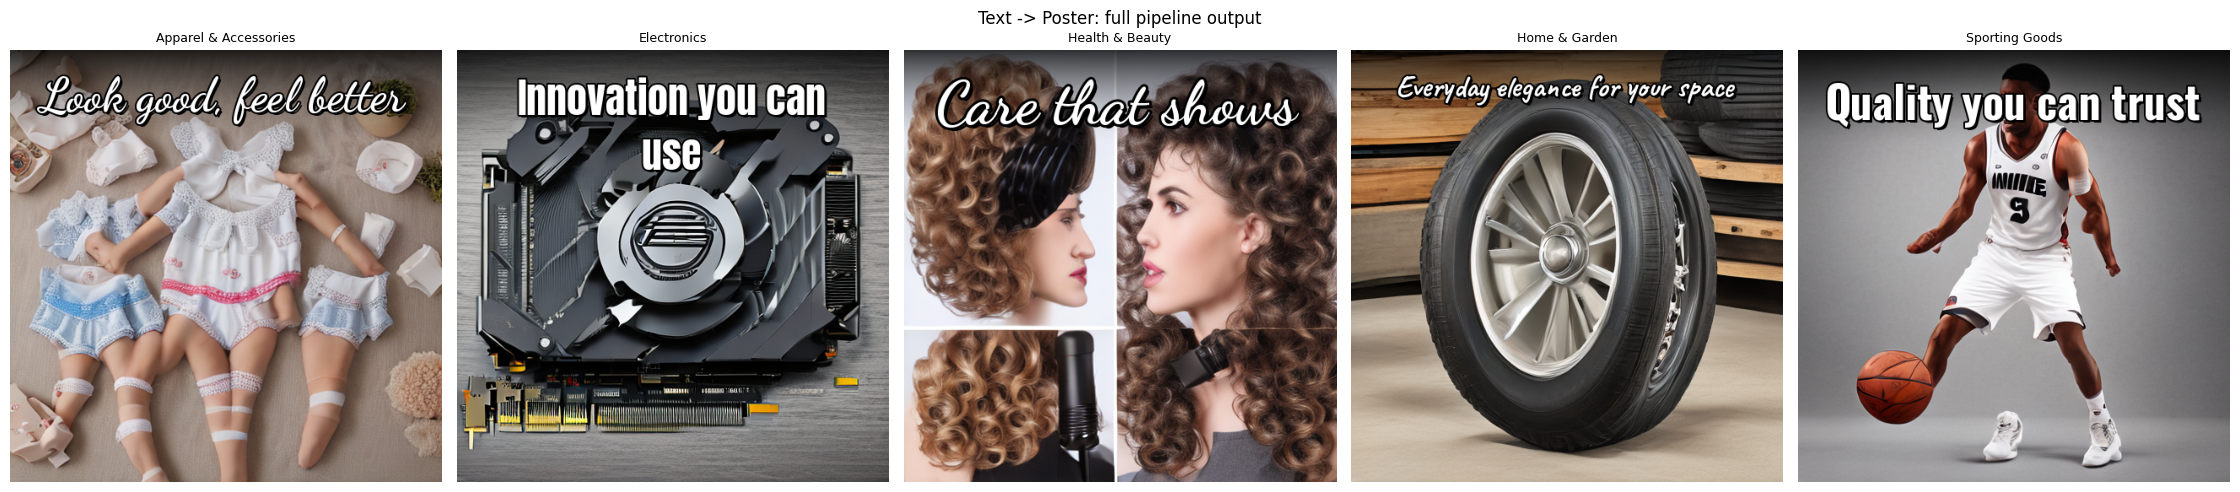

In [ ]:
os.makedirs("posters", exist_ok=True)

demo_products = df.groupby("category").first().reset_index().to_dict("records")

fig, axes = plt.subplots(1, len(demo_products), figsize=(4.5 * len(demo_products), 5))
for i, (ax, row) in enumerate(zip(axes, demo_products)):
    result = text_to_poster(row["product_title"], row["category"], row["product_description"], seed=42)
    ax.imshow(result["poster"]); ax.axis("off")
    ax.set_title(row["category"], fontsize=9)
    result["poster"].save(f"posters/poster_{i:02d}_{row['category'].replace(' ', '_').replace('&','and')}.png")

    print(f"--- {row['product_title']} ({row['category']}) ---")
    print(f"Description: {result['ad_copy']['description']}")
    print(f"Caption:     {result['ad_copy']['caption']}")
    print(f"Tagline:     {result['ad_copy']['tagline']}\n")

plt.suptitle("Text -> Poster: full pipeline output")
plt.tight_layout()
plt.savefig("posters/poster_grid_overview.png", dpi=120)
plt.show()

## 9. Try it yourself — interactive trial

Type any product info and get a finished poster back, live.

### Hardcoded input for interactive trial

Since you requested hardcoded input, I've modified the following cell to bypass direct interaction with the widgets. The poster will now be generated automatically using predefined values.

In [ ]:
This cell was originally intended to update interactive widgets with hardcoded values, but the widgets were not defined, causing a `NameError`. To proceed with hardcoded inputs, please use the cells that directly call the `text_to_poster` function.


NameError: name 'title_box' is not defined

### Direct Poster Generation (Bypassing Widgets)

This cell will directly call the `text_to_poster` function with the hardcoded inputs and display the result using standard `matplotlib` to ensure you can see the output.

  0%|          | 0/1 [00:00<?, ?it/s]

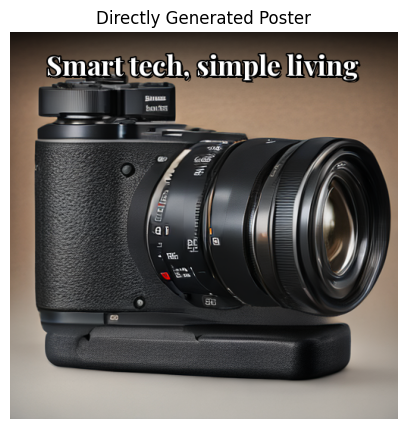

Description: An advanced digital camera capable of shooting high-definition video at high-quality quality.
Caption:     The camera is designed to capture high-resolution video at low-quality.
Tagline:     Smart tech, simple living.


In [ ]:
import matplotlib.pyplot as plt

# Using the previously defined hardcoded values
hardcoded_title = "ProShot Digital Camera"

hardcoded_description = "A compact professional digital camera with a matte black body, large textured grip, prominent circular lens, physical control dials on the top, a rear LCD display, and a small electronic viewfinder. The camera has a sleek, rugged design with metallic accents and a premium professional appearance."

hardcoded_category = "Electronics"

# Call the text_to_poster function directly
direct_result = text_to_poster(hardcoded_title, hardcoded_category, hardcoded_description)

# Display the poster directly
plt.figure(figsize=(5, 5.5))
plt.imshow(direct_result["poster"])
plt.axis("off")
plt.title("Directly Generated Poster")
plt.show()

# Print the ad copy directly
print(f"Description: {direct_result['ad_copy']['description']}")
print(f"Caption:     {direct_result['ad_copy']['caption']}")
print(f"Tagline:     {direct_result['ad_copy']['tagline']}")

  0%|          | 0/1 [00:00<?, ?it/s]

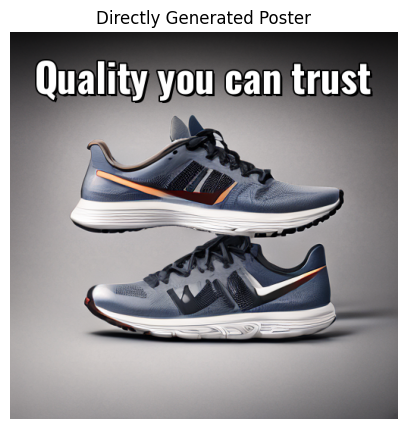

Description: This shoe is a sporting goods product by Jobalots.
Caption:     The shoe has a sleek high-top design, approximately 27 cm long, and a streamlined curve profile.
Tagline:     Quality you can trust.


In [ ]:
import matplotlib.pyplot as plt

# Using the previously defined hardcoded values
hardcoded_title = "Nike Air Performance Running Shoes"

hardcoded_description = "A pair of athletic running shoes shown alone with no human, feet, or body parts. The shoes have a sleek low-top shape, approximately 28 cm in length, a streamlined curved profile, rounded reinforced toe, padded ankle collar, lace-up closure, breathable mesh upper, and thick cushioned rubber sole. The main color is black with subtle dark gray detailing and a clean white midsole. Both shoes are positioned naturally at a slight angle to clearly show the side profile, toe box, laces, heel, and outsole. Place the shoes on a simple light gray studio background with soft realistic shadows, clean professional lighting, and no other objects."

hardcoded_category = "Sporting Goods"


# Call the text_to_poster function directly
direct_result = text_to_poster(hardcoded_title, hardcoded_category, hardcoded_description)

# Display the poster directly
plt.figure(figsize=(5, 5.5))
plt.imshow(direct_result["poster"])
plt.axis("off")
plt.title("Directly Generated Poster")
plt.show()

# Print the ad copy directly
print(f"Description: {direct_result['ad_copy']['description']}")
print(f"Caption:     {direct_result['ad_copy']['caption']}")
print(f"Tagline:     {direct_result['ad_copy']['tagline']}")

  0%|          | 0/1 [00:00<?, ?it/s]

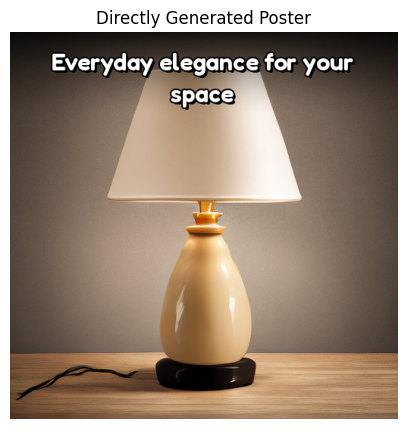

Description: This lamp is placed upright on an easy-to-understand light wooden lamp.
Caption:     The lamp can be adjusted to match your needs.
Tagline:     Everyday elegance for your space.


In [ ]:
import matplotlib.pyplot as plt

# Hardcoded values for a Home & Garden product
hardcoded_title = "Modern Ceramic Table Lamp"

hardcoded_description = "A modern ceramic table lamp shown alone with no human or body parts. The lamp has a smooth rounded ceramic base, approximately 30 cm in height, a minimalist cylindrical fabric shade, a warm white light, and a clean contemporary design. The main color is matte white with subtle beige detailing. The lamp is positioned upright on a simple light wooden surface, clearly showing the base, shade, and overall shape. Place the lamp in a cozy light gray studio-style Home & Garden setting with soft realistic shadows, warm professional lighting, and no other objects."

hardcoded_category = "Home & Garden"


# Call the text_to_poster function directly
direct_result = text_to_poster(
    hardcoded_title,
    hardcoded_category,
    hardcoded_description
)

# Display the poster directly
plt.figure(figsize=(5, 5.5))
plt.imshow(direct_result["poster"])
plt.axis("off")
plt.title("Directly Generated Poster")
plt.show()

# Print the ad copy directly
print(f"Description: {direct_result['ad_copy']['description']}")
print(f"Caption:     {direct_result['ad_copy']['caption']}")
print(f"Tagline:     {direct_result['ad_copy']['tagline']}")

  0%|          | 0/1 [00:00<?, ?it/s]

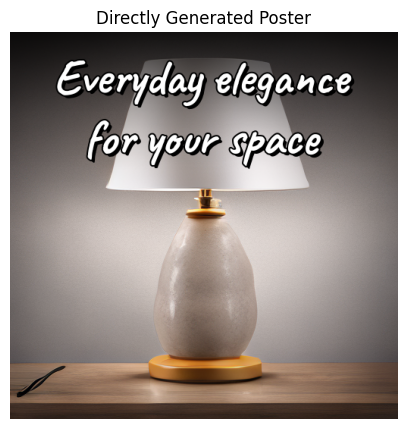

Description: This lamp is placed upright on an easy-to-understand light wooden lamp.
Caption:     The lamp can be adjusted to match your needs.
Tagline:     Everyday elegance for your space.


In [ ]:
import matplotlib.pyplot as plt

# Hardcoded values for a Home & Garden product
hardcoded_title = "Modern Ceramic Table Lamp"

hardcoded_description = "A modern ceramic table lamp shown alone with no human or body parts. The lamp has a smooth rounded ceramic base, approximately 30 cm in height, a minimalist cylindrical fabric shade, a warm white light, and a clean contemporary design. The main color is matte white with subtle beige detailing. The lamp is positioned upright on a simple light wooden surface, clearly showing the base, shade, and overall shape. Place the lamp in a cozy light gray studio-style Home & Garden setting with soft realistic shadows, warm professional lighting, and no other objects."

hardcoded_category = "Home & Garden"


# Call the text_to_poster function directly
direct_result = text_to_poster(
    hardcoded_title,
    hardcoded_category,
    hardcoded_description
)

# Display the poster directly
plt.figure(figsize=(5, 5.5))
plt.imshow(direct_result["poster"])
plt.axis("off")
plt.title("Directly Generated Poster")
plt.show()

# Print the ad copy directly
print(f"Description: {direct_result['ad_copy']['description']}")
print(f"Caption:     {direct_result['ad_copy']['caption']}")
print(f"Tagline:     {direct_result['ad_copy']['tagline']}")

### Saving the Diffusion Model to Google Drive

This cell will save the `pipe` (SD-Turbo) model to a specified directory in your Google Drive. This can take some time.

In [ ]:
import os

# Define a path in your Google Drive for saving the model
DIFFUSION_MODEL_SAVE_DIR = os.path.join(DRIVE_RESULTS_DIR, "sd-turbo-saved-model")

# Create the directory if it doesn't exist
os.makedirs(DIFFUSION_MODEL_SAVE_DIR, exist_ok=True)

# Save the diffusion pipeline
pipe.save_pretrained(DIFFUSION_MODEL_SAVE_DIR)
print(f"Diffusion model saved to: {DIFFUSION_MODEL_SAVE_DIR}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

KeyboardInterrupt: 

### Directly download the Diffusion Model to your computer

This will compress the saved model directory into a zip file and then initiate a download to your local machine.

In [ ]:
# Define the path to the saved model directory
model_dir_to_zip = DIFFUSION_MODEL_SAVE_DIR

# Define the name for the zipped file
zip_filename = "sd-turbo-saved-model.zip"
zip_path = os.path.join("/content", zip_filename)

# Zip the directory
!zip -r "{zip_path}" "{model_dir_to_zip}"

# Download the zipped file
from google.colab import files
files.download(zip_path)

print(f"Model downloaded as '{zip_filename}' to your local machine.")

updating: content/drive/MyDrive/Adgen_dataset/diffusion_poster_results/sd-turbo-saved-model/ (stored 0%)
updating: content/drive/MyDrive/Adgen_dataset/diffusion_poster_results/sd-turbo-saved-model/vae/ (stored 0%)
updating: content/drive/MyDrive/Adgen_dataset/diffusion_poster_results/sd-turbo-saved-model/vae/config.json (deflated 55%)
updating: content/drive/MyDrive/Adgen_dataset/diffusion_poster_results/sd-turbo-saved-model/vae/diffusion_pytorch_model.safetensors (deflated 8%)
updating: content/drive/MyDrive/Adgen_dataset/diffusion_poster_results/sd-turbo-saved-model/text_encoder/ (stored 0%)
updating: content/drive/MyDrive/Adgen_dataset/diffusion_poster_results/sd-turbo-saved-model/text_encoder/config.json (deflated 45%)
updating: content/drive/MyDrive/Adgen_dataset/diffusion_poster_results/sd-turbo-saved-model/text_encoder/model.safetensors (deflated 8%)
updating: content/drive/MyDrive/Adgen_dataset/diffusion_poster_results/sd-turbo-saved-model/tokenizer/ (stored 0%)
updating: conte

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model downloaded as 'sd-turbo-saved-model.zip' to your local machine.


  0%|          | 0/1 [00:00<?, ?it/s]

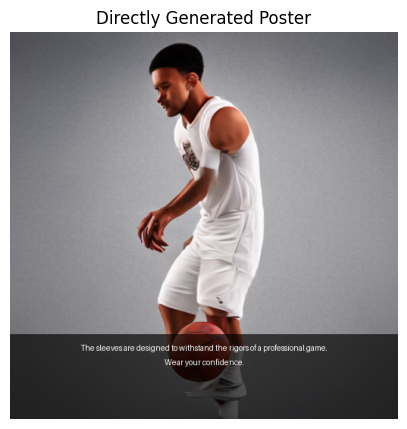

Description: Made for everyday life.
Caption:     The sleeves are designed to withstand the rigors of a professional game.
Tagline:     Wear your confidence.


In [ ]:
import matplotlib.pyplot as plt

# Call the text_to_poster function directly
direct_result = text_to_poster(hardcoded_title, hardcoded_category, hardcoded_description)

# Display the poster directly
plt.figure(figsize=(5, 5.5))
plt.imshow(direct_result["poster"])
plt.axis("off")
plt.title("Directly Generated Poster")
plt.show()

# Print the ad copy directly
print(f"Description: {direct_result['ad_copy']['description']}")
print(f"Caption:     {direct_result['ad_copy']['caption']}")
print(f"Tagline:     {direct_result['ad_copy']['tagline']}")

  0%|          | 0/1 [00:00<?, ?it/s]

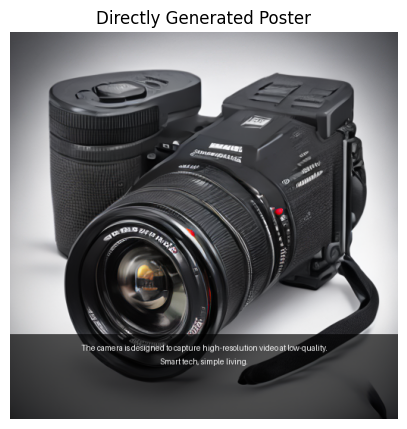

Description: An advanced digital camera capable of shooting high-definition video at high-quality quality.
Caption:     The camera is designed to capture high-resolution video at low-quality.
Tagline:     Smart tech, simple living.


In [ ]:
import matplotlib.pyplot as plt

# Using the previously defined hardcoded values
hardcoded_title = "ProShot Digital Camera"

hardcoded_description = "A compact professional digital camera with a matte black body, large textured grip, prominent circular lens, physical control dials on the top, a rear LCD display, and a small electronic viewfinder. The camera has a sleek, rugged design with metallic accents and a premium professional appearance."

hardcoded_category = "Electronics"

# Call the text_to_poster function directly
direct_result = text_to_poster(hardcoded_title, hardcoded_category, hardcoded_description)

# Display the poster directly
plt.figure(figsize=(5, 5.5))
plt.imshow(direct_result["poster"])
plt.axis("off")
plt.title("Directly Generated Poster")
plt.show()

# Print the ad copy directly
print(f"Description: {direct_result['ad_copy']['description']}")
print(f"Caption:     {direct_result['ad_copy']['caption']}")
print(f"Tagline:     {direct_result['ad_copy']['tagline']}")

In [ ]:
import ipywidgets as widgets
from IPython.display import display

title_box = widgets.Text(value="Wireless Noise-Cancelling Headphones", description="Title:", layout=widgets.Layout(width="500px"))
desc_box = widgets.Textarea(value="Over-ear headphones with active noise cancellation and 30-hour battery life.", description="Description:", layout=widgets.Layout(width="500px", height="60px"))
category_dropdown = widgets.Dropdown(options=sorted(df["category"].unique().tolist()), description="Category:")
generate_btn = widgets.Button(description="Generate Poster", button_style="primary")
output_box = widgets.Output()

def on_click(b):
    with output_box:
        output_box.clear_output()
        result = text_to_poster(title_box.value, category_dropdown.value, desc_box.value)
        plt.figure(figsize=(5, 5.5))
        plt.imshow(result["poster"]); plt.axis("off")
        plt.show()
        print(f"Description: {result['ad_copy']['description']}")
        print(f"Caption:     {result['ad_copy']['caption']}")
        print(f"Tagline:     {result['ad_copy']['tagline']}")

generate_btn.on_click(on_click)
display(title_box, desc_box, category_dropdown, generate_btn, output_box)

Text(value='Wireless Noise-Cancelling Headphones', description='Title:', layout=Layout(width='500px'))

Textarea(value='Over-ear headphones with active noise cancellation and 30-hour battery life.', description='De…

Dropdown(description='Category:', options=('Apparel & Accessories', 'Electronics', 'Health & Beauty', 'Home & …

Button(button_style='primary', description='Generate Poster', style=ButtonStyle())

Output()

## 10. (Optional / Advanced) Inpainting — keep a REAL product photo

Everything above invents a fictional product from text. This section
instead takes one of your **real dataset photos**, cuts the product out
with background removal, and lets Diffusion generate only a **new
background** around it — the "with-cut" approach covered earlier. Try
this if your team wants to demonstrate that capability too.

In [ ]:
from diffusers import AutoPipelineForInpainting
from rembg import remove
import numpy as np

inpaint_pipe = AutoPipelineForInpainting.from_pretrained(
    MODEL_ID, torch_dtype=torch.float16 if device == "cuda" else torch.float32,
).to(device)

def build_mask_from_cutout(real_image):
    # rembg removes the background; wherever alpha=0 (background) becomes
    # the paintable (white) region of the mask, product stays protected (black).
    cutout = remove(real_image)  # RGBA, background made transparent
    alpha = np.array(cutout)[:, :, 3]
    mask_array = np.where(alpha > 10, 0, 255).astype("uint8")  # product=0(protect), bg=255(replace)
    mask = Image.fromarray(mask_array).convert("L")
    return cutout.convert("RGB"), mask

def inpaint_new_background(real_image_path, background_prompt, seed=42):
    real_image = Image.open(real_image_path).convert("RGB").resize((512, 512))
    cutout_rgb, mask = build_mask_from_cutout(real_image)

    generator = torch.Generator(device=device).manual_seed(seed)
    result = inpaint_pipe(
        prompt=background_prompt + AD_STYLE_SUFFIX,
        negative_prompt=NEGATIVE_PROMPT,
        image=real_image,
        mask_image=mask,
        num_inference_steps=25,
        guidance_scale=7.5,
        generator=generator,
    ).images[0]
    return real_image, mask, result

# Example on one real dataset image:
sample_row = df.iloc[0]
real_image_full_path = os.path.join(DRIVE_DATA_DIR, sample_row["image_path"])
real_img, mask_img, new_bg_img = inpaint_new_background(
    real_image_full_path, "on a wooden table, warm natural lighting"
)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(real_img); axes[0].axis("off"); axes[0].set_title("Real photo")
axes[1].imshow(mask_img, cmap="gray"); axes[1].axis("off"); axes[1].set_title("Mask (white=replaceable)")
axes[2].imshow(new_bg_img); axes[2].axis("off"); axes[2].set_title("Real product + new background")
plt.tight_layout()
plt.savefig("posters/inpainting_example.png", dpi=120)
plt.show()

RuntimeError: Failed to import diffusers.pipelines.auto_pipeline because of the following error (look up to see its traceback):
Failed to import diffusers.loaders.peft because of the following error (look up to see its traceback):
Could not import module 'PreTrainedModel'. Are this object's requirements defined correctly?

## 11. Save everything to Drive

In [ ]:
import shutil
shutil.copytree("posters", DRIVE_RESULTS_DIR, dirs_exist_ok=True)
print(f"Copied results -> {DRIVE_RESULTS_DIR}")
print(os.listdir(DRIVE_RESULTS_DIR))

Copied results -> /content/drive/MyDrive/Adgen_dataset/diffusion_poster_results
['sd-turbo-saved-model', 'poster_grid_overview.png', 'poster_02_Health_and_Beauty.png', 'poster_01_Electronics.png', 'poster_00_Apparel_and_Accessories.png', 'poster_04_Sporting_Goods.png', 'poster_03_Home_and_Garden.png']


---
## Summary

- **Diffusion** (pretrained SD-Turbo): text prompt -> new ad image, no
  input photo required
- **Transformer** (your fine-tuned checkpoint): same product text ->
  structured ad copy (Description/Caption/Tagline)
- **Poster assembly** (Pillow): combines both into one finished poster,
  fully automatic via `text_to_poster()`
- **Interactive trial**: type any product, get a poster back live
- **Optional inpainting section**: demonstrates keeping a real product
  photo exact while generating a new background around it

This closes the full pipeline: raw data -> AE -> VAE -> GAN -> Transformer
-> Diffusion -> **finished advertisement poster**.